# YZM 411 — Ödev 1: Renk, Aydınlatma ve Örnekleme

## 1. Kurulum ve veri yolları

In [4]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

try:
    from google.colab.patches import cv2_imshow
except ImportError:
    cv2_imshow = None

# Kendi dosya yollarınızı buraya yazın.
IMAGE_PATHS = {
    "normal": Path("isik.jpg"),
    "golge": Path("golge.jpg"),
    "lamba": Path("lamba.jpg"),
}

# Aynı fiziksel bölgeden örneklemek için koordinatları kendiniz seçin.
# Koordinat sırası (x, y)'dir; NumPy erişimi img[y, x, kanal] şeklindedir.
SAMPLE_POINTS = [(100, 100), (200, 150), (300, 200)]

def read_bgr(path):
    image = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if image is None:
        raise FileNotFoundError(
            f"Görüntü okunamadı: {path}. IMAGE_PATHS değerini kontrol edin."
        )
    return image

images_bgr = {name: read_bgr(path) for name, path in IMAGE_PATHS.items()}
reference_shape = images_bgr["normal"].shape[:2]

for name, image in list(images_bgr.items()):
    if image.shape[:2] != reference_shape:
        images_bgr[name] = cv2.resize(
            image,
            (reference_shape[1], reference_shape[0]),
            interpolation=cv2.INTER_AREA,
        )

images_rgb = {
    name: cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    for name, image in images_bgr.items()
}

print("Görüntüler yüklendi:", ", ".join(images_bgr))
print("Ortak boyut:", reference_shape)

Görüntüler yüklendi: normal, golge, lamba
Ortak boyut: (3072, 4096)


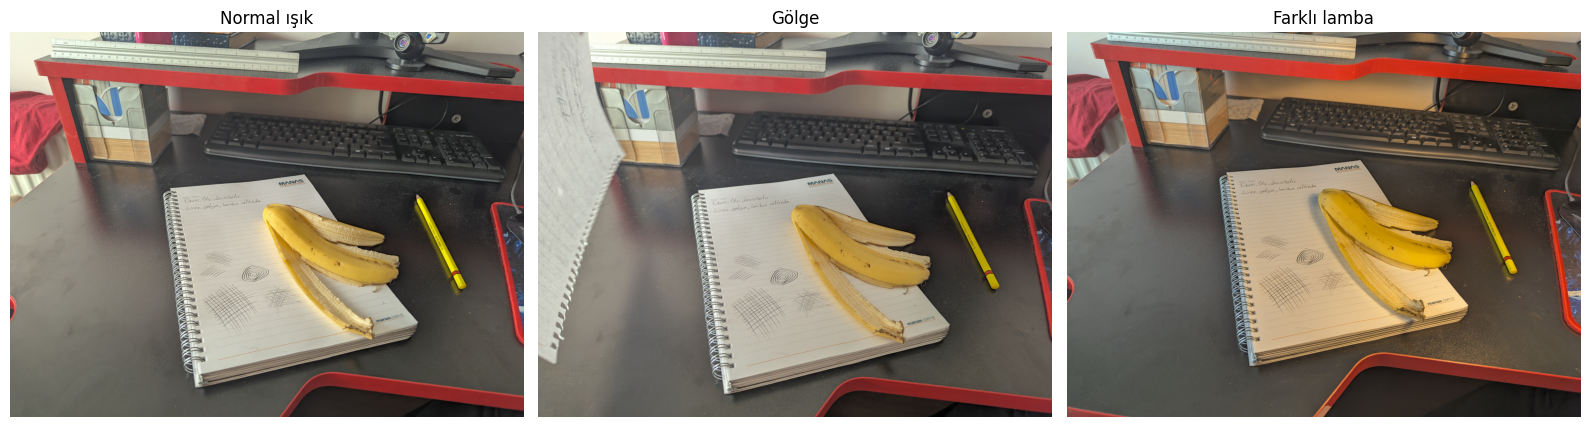

In [5]:
def show_images(images, titles, cols=3, figsize=(16, 5)):
    rows = int(np.ceil(len(images) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=figsize, squeeze=False)
    for ax, image, title in zip(axes.flat, images, titles):
        ax.imshow(image)
        ax.set_title(title)
        ax.axis("off")
    for ax in axes.flat[len(images):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

show_images(
    list(images_rgb.values()),
    ["Normal ışık", "Gölge", "Farklı lamba"],
)

## 2. Görüntünün sayısal yapısı (Hedef 1)

In [6]:
def image_info(image):
    return {
        "boyut (H, W, C)": image.shape,
        "veri tipi": str(image.dtype),
        "minimum": int(image.min()),
        "maksimum": int(image.max()),
    }

info_table = pd.DataFrame(
    {name: image_info(image) for name, image in images_bgr.items()}
).T
display(info_table)

height, width = images_bgr["normal"].shape[:2]
valid_points = [
    (x, y)
    for x, y in SAMPLE_POINTS
    if 0 <= x < width and 0 <= y < height
]
if len(valid_points) != len(SAMPLE_POINTS):
    print("Uyarı: Görüntü sınırları dışındaki noktalar atlandı.")

rows = []
for x, y in valid_points:
    for name, image in images_rgb.items():
        r, g, b = image[y, x]
        rows.append(
            {"koşul": name, "x": x, "y": y, "R": int(r), "G": int(g), "B": int(b)}
        )
pixel_table = pd.DataFrame(rows)
display(pixel_table)

# BGR ve RGB kanal sırasının aynı piksel üzerindeki farkı:
x, y = valid_points[0]
print("NumPy erişimi img[y, x, kanal]:")
print("BGR:", images_bgr["normal"][y, x])
print("RGB:", images_rgb["normal"][y, x])

,"boyut (H, W, C)",veri tipi,minimum,maksimum
normal,"(3072, 4096, 3)",uint8,0,255
golge,"(3072, 4096, 3)",uint8,0,255
lamba,"(3072, 4096, 3)",uint8,0,255


,koşul,x,y,R,G,B
0,normal,100,100,243,245,224
1,golge,100,100,199,200,195
2,lamba,100,100,202,215,208
3,normal,200,150,245,244,223
4,golge,200,150,199,200,194
5,lamba,200,150,216,219,212
6,normal,300,200,157,160,141
7,golge,300,200,203,204,196
8,lamba,300,200,172,68,65


NumPy erişimi img[y, x, kanal]:
BGR: [224 245 243]
RGB: [243 245 224]


## 3. Sabit renk eşikleriyle maske karşılaştırması (Hedef 2)

In [7]:
RGB_LOWER = np.array([150, 100, 0], dtype=np.uint8)
RGB_UPPER = np.array([255, 230, 120], dtype=np.uint8)
HSV_LOWER = np.array([10, 100, 80], dtype=np.uint8)
HSV_UPPER = np.array([40, 255, 255], dtype=np.uint8)

masks_rgb = {}
masks_hsv = {}
mask_rows = []

for name, image_bgr in images_bgr.items():
    image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    image_hsv = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2HSV)
    masks_rgb[name] = cv2.inRange(image_rgb, RGB_LOWER, RGB_UPPER)
    masks_hsv[name] = cv2.inRange(image_hsv, HSV_LOWER, HSV_UPPER)
    total_pixels = image_bgr.shape[0] * image_bgr.shape[1]
    mask_rows.extend(
        [
            {
                "koşul": name,
                "maske": "RGB",
                "seçilen piksel": int(np.count_nonzero(masks_rgb[name])),
                "alan oranı (%)": 100 * np.count_nonzero(masks_rgb[name]) / total_pixels,
            },
            {
                "koşul": name,
                "maske": "HSV",
                "seçilen piksel": int(np.count_nonzero(masks_hsv[name])),
                "alan oranı (%)": 100 * np.count_nonzero(masks_hsv[name]) / total_pixels,
            },
        ]
    )

mask_table = pd.DataFrame(mask_rows)
display(mask_table.round({"alan oranı (%)": 3}))

,koşul,maske,seçilen piksel,alan oranı (%)
0,normal,RGB,574603,4.567
1,normal,HSV,616488,4.899
2,golge,RGB,647794,5.148
3,golge,HSV,652099,5.182
4,lamba,RGB,1117551,8.881
5,lamba,HSV,1633921,12.985


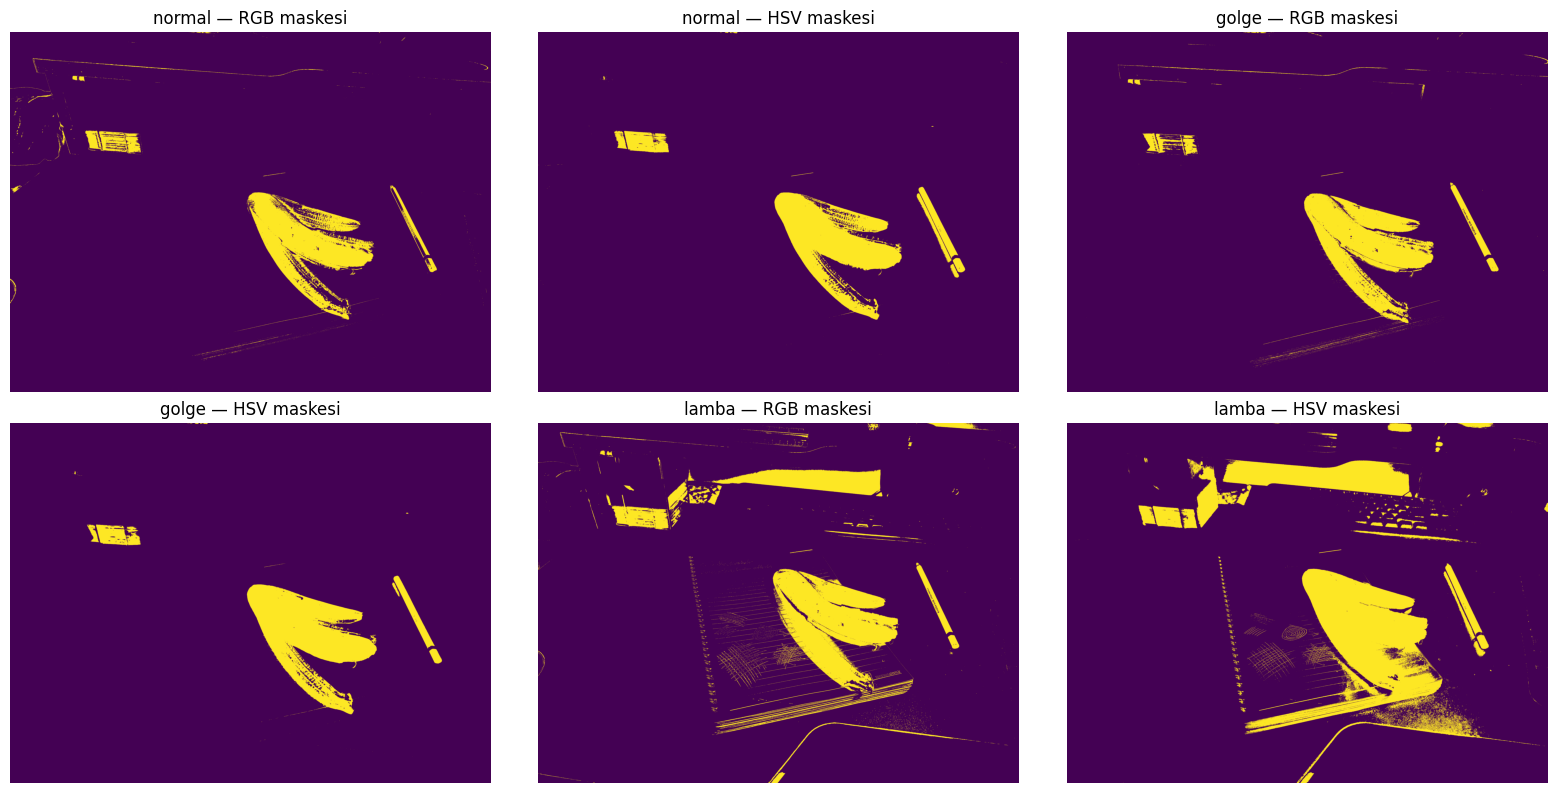

In [8]:
mask_display = []
mask_titles = []
for name in images_bgr:
    mask_display.extend([masks_rgb[name], masks_hsv[name]])
    mask_titles.extend([f"{name} — RGB maskesi", f"{name} — HSV maskesi"])
show_images(mask_display, mask_titles, cols=3, figsize=(16, 8))

## 4. Parlaklık ve gama dönüşümleri (Hedef 3)

,dönüşüm,ortalama,minimum,maksimum,255'e kırpılan kanal değeri,0'a kırpılan kanal değeri
0,orijinal,107.60,0,255,39754,27050
1,parlaklık +40,146.94,40,255,1430890,0
2,gama 0.5,158.82,0,255,39754,27050
3,gama 2.0,58.20,0,255,39754,154304


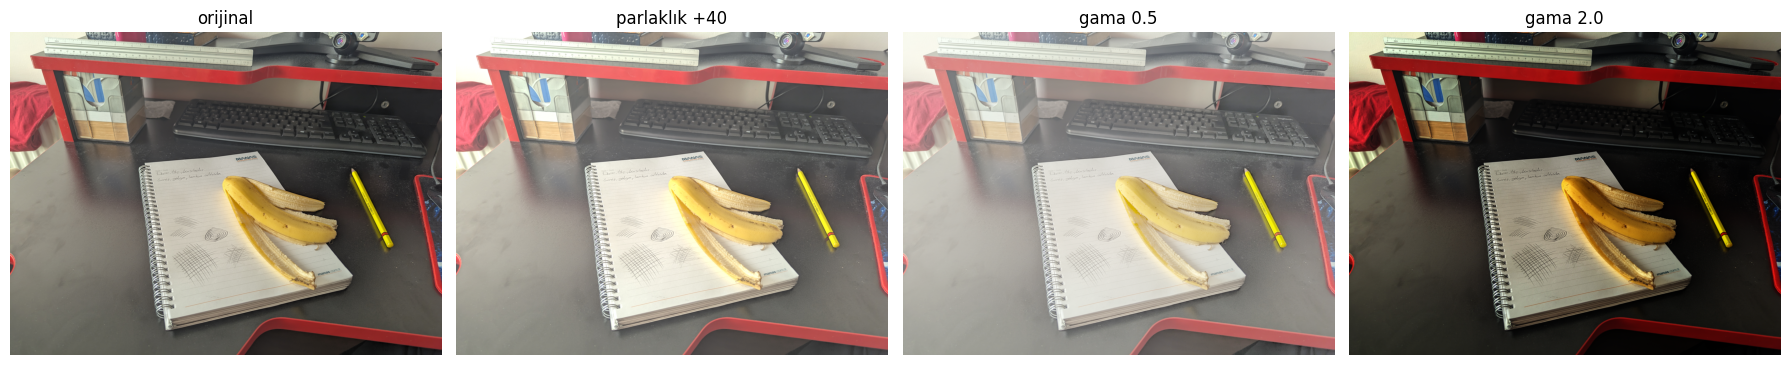

In [9]:
def brightness_shift(image_rgb, b=40):
    return np.clip(image_rgb.astype(np.float32) + b, 0, 255).astype(np.uint8)

def gamma_transform(image_rgb, gamma):
    normalized = image_rgb.astype(np.float32) / 255.0
    return np.clip(255.0 * normalized**gamma, 0, 255).astype(np.uint8)

normal_rgb = images_rgb["normal"]
transformed = {
    "orijinal": normal_rgb,
    "parlaklık +40": brightness_shift(normal_rgb, b=40),
    "gama 0.5": gamma_transform(normal_rgb, gamma=0.5),
    "gama 2.0": gamma_transform(normal_rgb, gamma=2.0),
}

transform_rows = []
for name, image in transformed.items():
    transform_rows.append(
        {
            "dönüşüm": name,
            "ortalama": float(image.mean()),
            "minimum": int(image.min()),
            "maksimum": int(image.max()),
            "255'e kırpılan kanal değeri": int(np.count_nonzero(image == 255)),
            "0'a kırpılan kanal değeri": int(np.count_nonzero(image == 0)),
        }
    )
transform_table = pd.DataFrame(transform_rows)
display(transform_table.round({"ortalama": 2}))

show_images(
    list(transformed.values()),
    list(transformed.keys()),
    cols=4,
    figsize=(18, 5),
)

## 5. 1/4 oranında küçültme ve geri büyütme (Hedef 4)

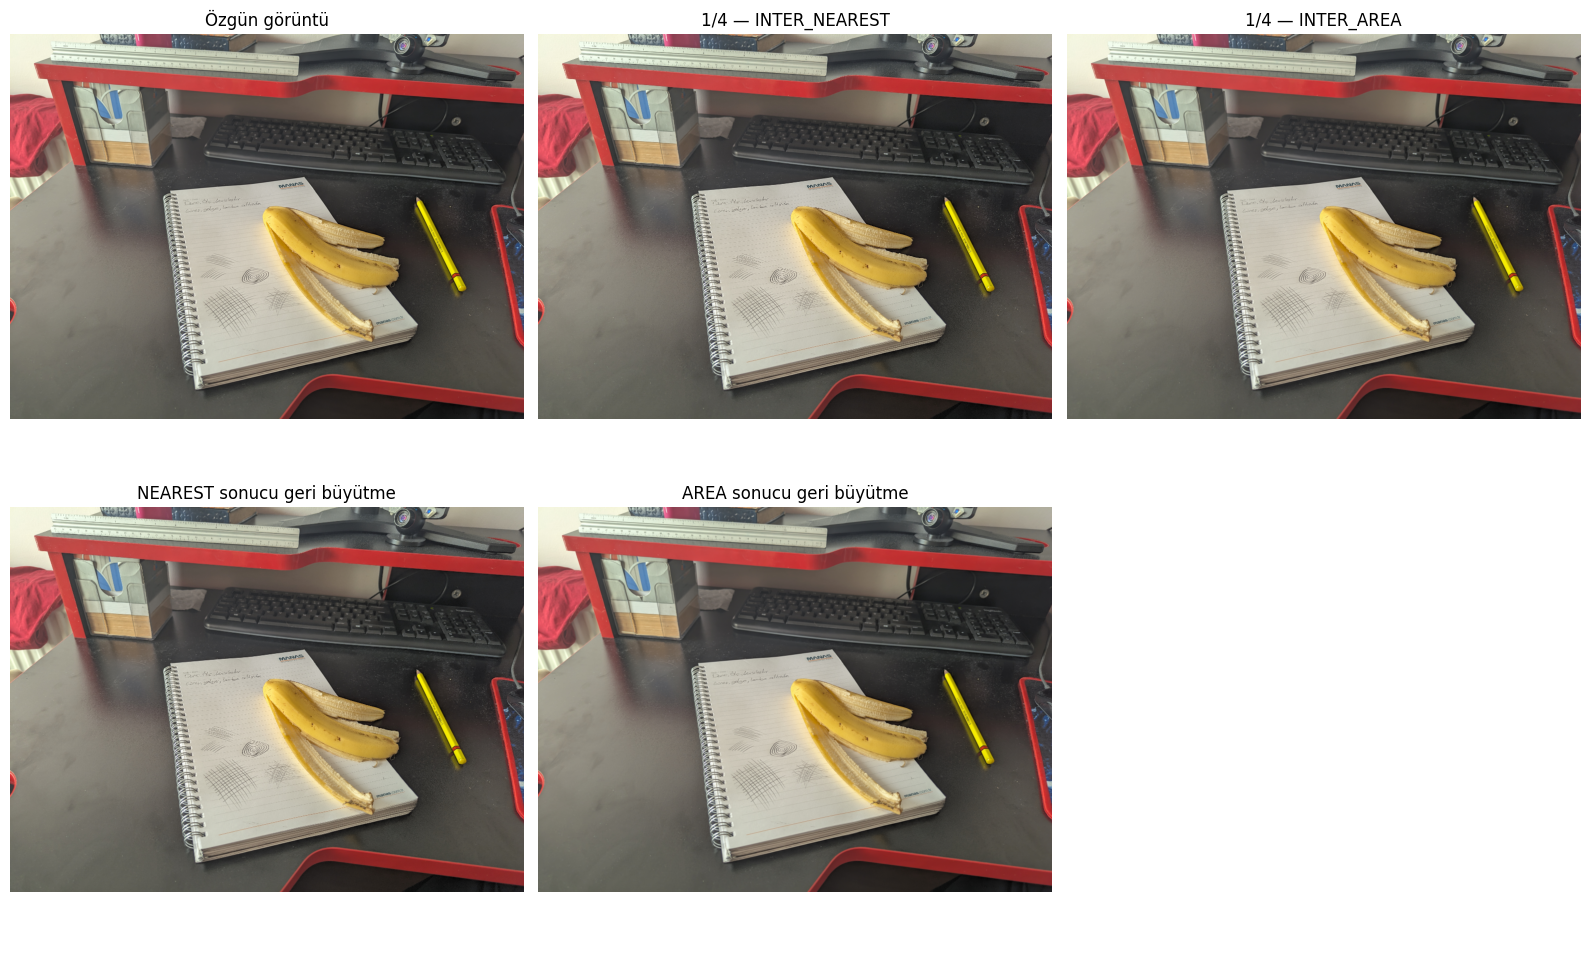

,görüntü,ortalama mutlak piksel farkı,gri seviye standart sapması
0,özgün,0.00,56.07
1,NEAREST geri büyütülmüş,4.09,56.11
2,AREA geri büyütülmüş,2.83,55.70


In [10]:
original_bgr = images_bgr["normal"]
h, w = original_bgr.shape[:2]
reduced_size = (max(1, w // 4), max(1, h // 4))

reduced_nearest = cv2.resize(
    original_bgr, reduced_size, interpolation=cv2.INTER_NEAREST
)
reduced_area = cv2.resize(
    original_bgr, reduced_size, interpolation=cv2.INTER_AREA
)
restored_nearest = cv2.resize(
    reduced_nearest, (w, h), interpolation=cv2.INTER_NEAREST
)
restored_area = cv2.resize(
    reduced_area, (w, h), interpolation=cv2.INTER_NEAREST
)

sampling_images = [
    cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    for image in [original_bgr, reduced_nearest, reduced_area, restored_nearest, restored_area]
]
sampling_titles = [
    "Özgün görüntü",
    "1/4 — INTER_NEAREST",
    "1/4 — INTER_AREA",
    "NEAREST sonucu geri büyütme",
    "AREA sonucu geri büyütme",
]
show_images(sampling_images, sampling_titles, cols=3, figsize=(16, 10))

# Kenar değişimini sayısal olarak destekleyen basit bir karşılaştırma.
gray_original = cv2.cvtColor(original_bgr, cv2.COLOR_BGR2GRAY)
gray_nearest = cv2.cvtColor(restored_nearest, cv2.COLOR_BGR2GRAY)
gray_area = cv2.cvtColor(restored_area, cv2.COLOR_BGR2GRAY)
sampling_table = pd.DataFrame(
    {
        "görüntü": ["özgün", "NEAREST geri büyütülmüş", "AREA geri büyütülmüş"],
        "ortalama mutlak piksel farkı": [
            0.0,
            float(np.mean(np.abs(gray_original.astype(float) - gray_nearest))),
            float(np.mean(np.abs(gray_original.astype(float) - gray_area))),
        ],
        "gri seviye standart sapması": [
            float(gray_original.std()),
            float(gray_nearest.std()),
            float(gray_area.std()),
        ],
    }
)
display(sampling_table.round(2))

Python: 3.13.18
OpenCV: 5.0.0
NumPy: 2.4.6
Pandas: 2.2.3